# 03 · ItemKNN: рекомендации по совместным просмотрам

Следующий шаг — искать похожие объекты по их зрителям. Если два фильма часто встречаются у одних пользователей, один из них может стать рекомендацией после другого.

Для каждого объекта сохраняю ближайших соседей по косинусному сходству. Оценка кандидата — сумма сходств с объектами из истории. Проверяю ту же неделю и тех же пользователей, что и у Popularity.

## Данные

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from threadpoolctl import threadpool_limits

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
DATA_DIR = Path(os.environ.get("KION_DATA_DIR", ROOT / "data"))
REPORTS = ROOT / "reports" / "full"
K = 10
blas_limit = threadpool_limits(limits=1, user_api="blas")
plt.rcParams.update(
    {
        "figure.figsize": (9, 4),
        "font.size": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

In [2]:
from kion_recsys.models import ItemKNNRecommender, PopularRecommender

In [3]:
from kion_recsys.data import TrainingData, load_interactions, split_interactions
from kion_recsys.metrics import build_targets, ranking_metrics

interactions = load_interactions(DATA_DIR)
raw_train, raw_validation, raw_test = split_interactions(interactions, None)
train, validation, test = split_interactions(interactions)
training_data = TrainingData.from_frame(train, raw_train)
validation_targets = build_targets(raw_train, validation)
selected = json.loads((REPORTS / "selected_params.json").read_text())
metrics = pd.read_csv(REPORTS / "metrics.csv")
print(
    f"Train: {len(train):,} positive pairs; "
    f"validation users: {len(validation_targets):,}"
)

Train: 2,686,055 positive pairs; validation users: 103,258


## Сходство объектов

Для бинарной матрицы взаимодействий косинусное сходство двух объектов вычисляется по числу общих зрителей:

$$
\operatorname{sim}(i,j)=\frac{|U_i\cap U_j|}{\sqrt{|U_i|\,|U_j|}}.
$$

Модель хранит разреженную матрицу пользователь–объект и только ближайших соседей каждого объекта. Объекты с менее чем 20 взаимодействиями исключаются из расчёта сходств; для недостаточного числа кандидатов используется Popularity fallback. Это ограничение не удаляет такие объекты из обучающего каталога.

Матрица сходств рассчитывается блоками, затем для каждой строки сохраняется top-N. Полная плотная item–item матрица не хранится; равные scores упорядочены по item ID.

In [4]:
grid = pd.read_csv(REPORTS / "validation_grid.csv")
display(
    grid.loc[grid.model.eq("ItemKNN"), ["params", "MAP@10", "Recall@10", "Coverage"]]
)
knn = ItemKNNRecommender(**selected["ItemKNN"]).fit(training_data)
print(f"Training items: {knn.n_items:,}; stored similarities: {knn.similarity.nnz:,}")

,params,MAP@10,Recall@10,Coverage
1,"{""neighbors"": 50, ""min_item_interactions"": 20}",0.136933,0.266970,0.343394
2,"{""neighbors"": 100, ""min_item_interactions"": 20}",0.137368,0.268041,0.343394


Training items: 13,087; stored similarities: 504,352


## Валидация и сравнение с Popularity

In [5]:
popular = PopularRecommender().fit(training_data)

popular_recs = popular.recommend(validation_targets, k=K)
knn_recs = knn.recommend(validation_targets, k=K)

popular_metrics = ranking_metrics(
    popular_recs, validation_targets, popular.n_items, k=K
)
knn_metrics = ranking_metrics(knn_recs, validation_targets, knn.n_items, k=K)

comparison = pd.DataFrame(
    [popular_metrics, knn_metrics], index=["Popularity", "ItemKNN"]
)
display(comparison.round(4))

,MAP@10,Recall@10,NDCG@10,HitRate@10,Coverage,Users
Popularity,0.1351,0.2556,0.1751,0.3311,0.0026,103258
ItemKNN,0.1374,0.2680,0.1812,0.3554,0.3434,103258


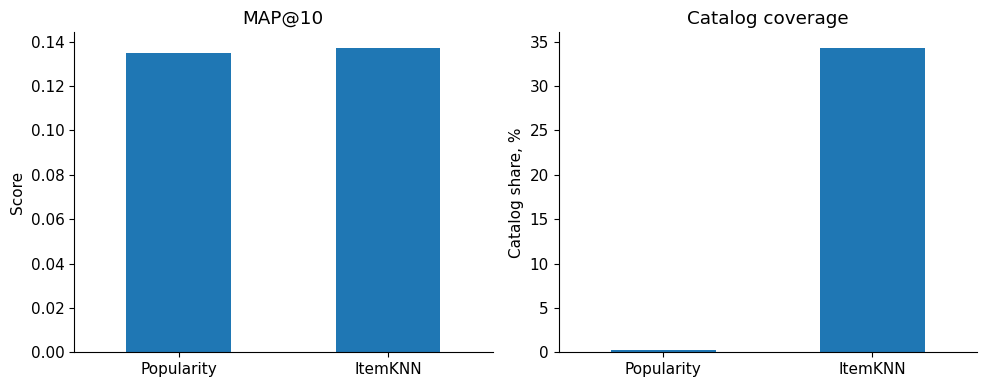

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

comparison["MAP@10"].plot.bar(ax=axes[0], rot=0)
axes[0].set(title="MAP@10", ylabel="Score")

comparison["Coverage"].mul(100).plot.bar(ax=axes[1], rot=0)
axes[1].set(title="Catalog coverage", ylabel="Catalog share, %")

plt.tight_layout()
plt.show()

## Разрез по активности пользователей

Качество проверяется отдельно для пользователей с короткой и длинной историей. Для каждой группы считается HitRate@10 — доля пользователей хотя бы с одним релевантным объектом в Top-10.

In [7]:
user_activity = train.groupby("user_id").size()

activity_results = pd.DataFrame(
    {
        "interactions": user_activity.reindex(validation_targets).fillna(0).to_numpy(),
        "Popularity": [
            bool(set(popular_recs[user_id]) & relevant)
            for user_id, relevant in validation_targets.items()
        ],
        "ItemKNN": [
            bool(set(knn_recs[user_id]) & relevant)
            for user_id, relevant in validation_targets.items()
        ],
    }
)

activity_results["group"] = pd.cut(
    activity_results["interactions"],
    bins=[-1, 0, 1, 5, 20, float("inf")],
    labels=["cold", "1", "2–5", "6–20", "21+"],
)

segment_metrics = activity_results.groupby("group", observed=True).agg(
    users=("interactions", "size"),
    popularity_hit_rate=("Popularity", "mean"),
    itemknn_hit_rate=("ItemKNN", "mean"),
)
display(segment_metrics.round(4))

,users,popularity_hit_rate,itemknn_hit_rate
group,,,
cold,36456,0.4860,0.4860
1,11792,0.3758,0.3265
2–5,23972,0.2802,0.3101
6–20,22985,0.1862,0.2555
21+,8053,0.1289,0.2263


## Финальная оценка на Test

Настройки модели фиксированы по результатам Validation. На Test обе модели обучаются на полной доступной истории Train + Validation.

In [8]:
test_comparison = metrics.query(
    "split == 'test' and model in ['Popularity', 'ItemKNN']"
)
display(test_comparison.set_index("model").drop(columns=["split", "seconds"]).round(4))

,MAP@10,Recall@10,NDCG@10,HitRate@10,Coverage,Users
model,,,,,,
Popularity,0.1215,0.2366,0.1598,0.3127,0.0027,106819
ItemKNN,0.1257,0.2487,0.1673,0.3365,0.3462,106819


## Выводы

ItemKNN немного улучшил MAP@10: **0.1257** против **0.1215** у Popularity. Покрытие выросло с 0.27% до 34.6%.

Разрез по истории объясняет, почему общий прирост небольшой. При одном положительном просмотре Popularity всё ещё лучше. Начиная с группы 2–5 просмотров ItemKNN уже выигрывает по HitRate. Когда истории нет, обе модели используют один и тот же список популярности.

Это полезный простой вариант: модель легко объяснить через соседние объекты. Дальше проверю, сможет ли ALS лучше использовать разреженную историю.